# 05 — QLoRA Fine-Tuning: Quantize to 4-bit, Then LoRA

> Part of the [SLM Fine-Tuning Tutorial](https://github.com/Kumarjit-Pathak/finetuning-slm)

**Status**: ✅ Complete | **Models**: SmolLM2-135M (demo) + estimated for 360M/1.5B | **Device**: Apple Silicon (MPS)

---

## What You'll Learn

| Section | Topic |
|---|---|
| Step 1 | Dataset: instruction-following pairs |
| Step 2 | NF4 quantization — how 4-bit NormalFloat works |
| Step 3 | QLoRA = quantize base model + LoRA adapters on top |
| Step 4 | "The Impossible Demo" — why 1.5B fits in 4-bit when full FT doesn't |
| Step 5 | Memory comparison chart — Full FT vs LoRA vs DoRA vs QLoRA |
| 🔴 Step 6 | Failure point — quantization accuracy degradation (perplexity comparison) |
| Step 7 | Apple Silicon note — bitsandbytes 4-bit on MPS status |

---

## The QLoRA Breakthrough

QLoRA (Dettmers et al., 2023) made it possible to fine-tune **billion-parameter models on a single GPU**:

```
Without QLoRA:  Llama-2-7B  full FT → needs ~112 GB VRAM  ← impossible on any consumer GPU
With QLoRA:     Llama-2-7B  QLoRA  → needs ~10 GB VRAM   ← fits on a single RTX 3090!
```

**The trick**: Quantize the frozen base model to **4-bit NF4**, apply LoRA adapters in bf16, train only the adapters.

```
Memory = frozen base (4-bit) + trainable adapters (bf16) + optimizer states (bf16)
       ≈ model_params × 0.5 bytes  +  adapter_params × 4 bytes  +  overhead
```

In [1]:
# ── Colab / Local environment check ──────────────────────────────────────────
import importlib, subprocess, sys

REQUIRED = {
    "torch": "torch", "transformers": "transformers",
    "peft": "peft", "bitsandbytes": "bitsandbytes",
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print(f"Installing: {missing}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

import torch, transformers, peft, bitsandbytes as bnb
print("✅ All required packages are installed!")
print(f"   torch {torch.__version__} | transformers {transformers.__version__} | "
      f"peft {peft.__version__} | bitsandbytes {bnb.__version__}")

✅ All required packages are installed!
   torch 2.13.0 | transformers 5.14.1 | peft 0.19.1 | bitsandbytes 0.49.2


In [2]:
import torch, time, gc, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
warnings.filterwarnings("ignore")

from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import (LoraConfig, get_peft_model, TaskType,
                  prepare_model_for_kbit_training)
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

# ── Device ────────────────────────────────────────────────────────────────────
if torch.backends.mps.is_available():
    DEVICE  = torch.device("mps")
    BACKEND = "Metal Performance Shaders (Apple Silicon)"
elif torch.cuda.is_available():
    DEVICE  = torch.device("cuda")
    BACKEND = f"CUDA ({torch.cuda.get_device_name(0)})"
else:
    DEVICE  = torch.device("cpu")
    BACKEND = "CPU"

# ── Model selection (SmolLM2-135M confirmed cached on this machine) ───────────
_HF_CACHE  = os.path.expanduser("~/.cache/huggingface/hub")
DEMO_MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct"   # 135M — cached + bitsandbytes 4-bit verified on MPS
BIG_MODEL  = "Qwen/Qwen2.5-1.5B-Instruct"             # 1.5B — tokenizer cached; use theoretical estimates for memory chart

MAX_LENGTH  = 128
TRAIN_STEPS = 35

# ── Memory helpers ────────────────────────────────────────────────────────────
def get_mem_gb():
    if DEVICE.type == "mps":
        return torch.mps.current_allocated_memory() / 1e9
    elif DEVICE.type == "cuda":
        return torch.cuda.memory_allocated() / 1e9
    return 0.0

def free_memory(*models):
    for m in models:
        del m
    gc.collect()
    if DEVICE.type == "mps":
        torch.mps.empty_cache()
    elif DEVICE.type == "cuda":
        torch.cuda.empty_cache()

def model_size_gb_fp32(n_params): return n_params * 4 / 1e9
def model_size_gb_4bit(n_params): return n_params * 0.5 / 1e9   # ~0.5 bytes per param avg

print(f"🖥️  Device: {DEVICE} | Backend: {BACKEND}")
print(f"📦 Demo model:  {DEMO_MODEL}")
print(f"📦 Large model: {BIG_MODEL} (theoretical reference)")
print(f"🔧 Demo steps per experiment: {TRAIN_STEPS}")

🖥️  Device: mps | Backend: Metal Performance Shaders (Apple Silicon)
📦 Demo model:  HuggingFaceTB/SmolLM2-135M-Instruct
📦 Large model: Qwen/Qwen2.5-1.5B-Instruct (theoretical reference)
🔧 Demo steps per experiment: 35


## Step 1 — Dataset: Instruction-Following Pairs

Same 20 factual Q&A pairs used in Notebook 04, repeated for volume. Identical to LoRA setup — the dataset preparation is unchanged; only the model loading strategy changes.

> **This is the power of PEFT**: swap `get_peft_model()` for `prepare_model_for_kbit_training()` + `get_peft_model()` and you get QLoRA. Your data pipeline never changes.

In [3]:
PAIRS = [
    ("What is photosynthesis?", "Photosynthesis converts sunlight, water, and CO₂ into glucose and oxygen."),
    ("Explain Newton's first law.", "An object in motion stays in motion unless acted on by a net external force."),
    ("What is the speed of light?", "The speed of light in vacuum is ~299,792,458 m/s, denoted c."),
    ("Define machine learning.", "ML: systems learn patterns from data to make predictions without explicit programming."),
    ("What is the Pythagorean theorem?", "In a right triangle: a² + b² = c², where c is the hypotenuse."),
    ("Translate 'hello' to French.", "'Hello' in French is 'bonjour'."),
    ("What causes rainbows?", "Rainbows form when sunlight refracts, disperses, and reflects inside water droplets."),
    ("Summarise the water cycle.", "Evaporation → condensation → precipitation → runoff → repeat."),
    ("What is DNA?", "DNA is the double-helix molecule encoding genetic instructions as base-pair sequences."),
    ("Explain gravity.", "Gravity: attractive force between masses; Einstein describes it as spacetime curvature."),
    ("What is the capital of Japan?", "The capital of Japan is Tokyo."),
    ("Define an algorithm.", "A finite, ordered set of instructions for solving a well-defined problem."),
    ("What is climate change?", "Long-term shift in global temperatures, primarily from human CO₂ emissions."),
    ("Explain the Doppler effect.", "Frequency increases as source/observer approach; decreases as they recede."),
    ("What is a neural network?", "Layered nodes learning non-linear input-output mappings from data."),
    ("Describe the water molecule.", "H₂O: two O–H bonds at ~104.5°, polar, permanent dipole moment."),
    ("What is special relativity?", "Speed of light is constant for all observers; time/length are relative to velocity."),
    ("What is inflation?", "Sustained increase in general price levels, reducing purchasing power."),
    ("Explain blockchain.", "Distributed, cryptographically linked transaction records maintained by consensus."),
    ("What is a photon?", "Massless quantum of light; energy E = hf where h is Planck's constant."),
] * 5  # 100 examples

print("Loading tokenizer…")
try:
    tokenizer = AutoTokenizer.from_pretrained(DEMO_MODEL)
    print("   ✅ Hub")
except Exception:
    tokenizer = AutoTokenizer.from_pretrained(DEMO_MODEL, local_files_only=True)
    print("   ⚠️  cached")

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

class InstructDataset(Dataset):
    def __init__(self, pairs):
        self.encodings = []
        for q, a in pairs:
            prompt = f"<|im_start|>user\n{q}<|im_end|>\n<|im_start|>assistant\n{a}<|im_end|>"
            enc = tokenizer(prompt, max_length=MAX_LENGTH, truncation=True,
                            padding="max_length", return_tensors="pt")
            self.encodings.append({k: v.squeeze(0) for k, v in enc.items()})
    def __len__(self):  return len(self.encodings)
    def __getitem__(self, i): return self.encodings[i]

split        = int(len(PAIRS) * 0.8)
train_loader = DataLoader(InstructDataset(PAIRS[:split]), batch_size=4, shuffle=True,  drop_last=True)
val_loader   = DataLoader(InstructDataset(PAIRS[split:]), batch_size=4, shuffle=False, drop_last=False)

print(f"📚 Train: {split} | Val: {len(PAIRS) - split} instruction pairs")

Loading tokenizer…
   ✅ Hub
📚 Train: 80 | Val: 20 instruction pairs


## Step 2 — NF4 Quantization: What's in the Box?

### The Maths Behind 4-bit NormalFloat

Standard float32 uses **32 bits per parameter**. NF4 (NormalFloat 4-bit) uses **4 bits** — an 8× compression.

**Key insight**: Neural network weights tend to follow a **normal (Gaussian) distribution**. NF4 exploits this by choosing 16 quantisation levels that are *information-theoretically optimal for Gaussian data*:

```
NF4 levels (symmetric, 16 values):
  [-1.0, -0.6962, -0.5250, -0.3949, -0.2844, -0.1848, -0.0911, 0.0,
    0.0796,  0.1609,  0.2461,  0.3379,  0.4407,  0.5626,  0.7230, 1.0]
  └── Denser near 0 (where most weights cluster) ──┘
```

Compared to uniform 4-bit quantisation, NF4 loses **less precision** because it places more quantisation levels where the data actually is.

### Double Quantisation (Optional)

bitsandbytes also supports **double quantisation**: quantise the quantisation constants themselves. This saves an extra ~0.37 bits per parameter — small but free.

### The QLoRA Recipe

```
① Load base model in NF4 4-bit (frozen, ~50% memory of fp16)
      ↓
② prepare_model_for_kbit_training()  ← cast norms to fp32, enable grad checkpointing
      ↓
③ Apply LoRA adapters (r=16, bf16)  ← only adapters get gradients
      ↓
④ Train adapters with AdamW          ← optimizer states for adapters only (tiny!)
      ↓
⑤ Save adapters (~10 MB file)       ← merge back when deploying
```

### bitsandbytes config

```python
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",          # NormalFloat 4-bit
    bnb_4bit_compute_dtype=torch.bfloat16,  # upcasts to bf16 for computation
    bnb_4bit_use_double_quant=True,     # quantise the quant constants too
)
```

In [4]:
# ── QLoRA training helper ─────────────────────────────────────────────────────
BNB_CONFIG = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

def run_qlora_experiment(model_name, rank=16, alpha=32,
                         target_modules=None, steps=TRAIN_STEPS, label="QLoRA"):
    if target_modules is None:
        target_modules = ["q_proj", "v_proj"]

    # 1) Load base model in 4-bit NF4
    try:
        base = AutoModelForCausalLM.from_pretrained(
            model_name, quantization_config=BNB_CONFIG, device_map="auto",
        )
    except Exception:
        base = AutoModelForCausalLM.from_pretrained(
            model_name, quantization_config=BNB_CONFIG, device_map="auto",
            local_files_only=True,
        )

    mem_loaded = get_mem_gb()

    # 2) Prepare for k-bit training (upcast norms, enable grad checkpointing)
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=False)

    # 3) Apply LoRA adapters
    cfg = LoraConfig(r=rank, lora_alpha=alpha, target_modules=target_modules,
                     lora_dropout=0.05, bias="none", task_type=TaskType.CAUSAL_LM)
    model = get_peft_model(base, cfg)

    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    # Adapter device (adapters are in bf16 on the model's primary device)
    model_dev = next(p for p in model.parameters() if p.requires_grad).device

    # 4) Train
    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-4)
    model.train()
    train_losses = []
    t0, step = time.time(), 0

    for batch in train_loader:
        if step >= steps:
            break
        ids    = batch["input_ids"].to(model_dev)
        attn   = batch["attention_mask"].to(model_dev)
        labels = ids.clone()
        labels[attn == 0] = -100

        out  = model(input_ids=ids, attention_mask=attn, labels=labels)
        loss = out.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad], 1.0
        )
        optimizer.step()
        optimizer.zero_grad()
        train_losses.append(loss.item())
        step += 1

    train_time = time.time() - t0

    # 5) Validation
    model.eval()
    val_losses = []
    with torch.no_grad():
        for batch in val_loader:
            ids    = batch["input_ids"].to(model_dev)
            attn   = batch["attention_mask"].to(model_dev)
            labels = ids.clone()
            labels[attn == 0] = -100
            out = model(input_ids=ids, attention_mask=attn, labels=labels)
            val_losses.append(out.loss.item())

    mem_peak = get_mem_gb()
    result = dict(
        label=label, total_params=total, trainable_params=trainable,
        trainable_pct=100 * trainable / total,
        train_losses=train_losses,
        final_train_loss=float(np.mean(train_losses[-5:])),
        final_val_loss=float(np.mean(val_losses)),
        train_time=train_time, mem_loaded_gb=mem_loaded, mem_peak_gb=mem_peak,
    )
    free_memory(model, base)

    print(f"[{label:25s}] params={trainable:>8,} ({result['trainable_pct']:.3f}%) | "
          f"train={result['final_train_loss']:.4f} | val={result['final_val_loss']:.4f} | "
          f"{train_time:.1f}s | loaded={mem_loaded:.2f}GB | peak={mem_peak:.2f}GB")
    return result


# ── Step 3 — Run QLoRA on SmolLM2-135M ───────────────────────────────────────
print("=" * 70)
print("QLoRA: SmolLM2-135M-Instruct in 4-bit NF4 + LoRA r=16")
print("=" * 70)
qlora_result = run_qlora_experiment(
    model_name=DEMO_MODEL, rank=16, alpha=32,
    target_modules=["q_proj", "v_proj"], label="QLoRA r=16 (135M, 4-bit)"
)

# Also run regular LoRA (fp32) on same model for comparison
print("\nRunning LoRA fp32 for side-by-side comparison…")
def run_lora_fp32(steps=TRAIN_STEPS, label="LoRA r=16 (135M, fp32)"):
    try:
        base = AutoModelForCausalLM.from_pretrained(DEMO_MODEL, dtype=torch.float32)
    except Exception:
        base = AutoModelForCausalLM.from_pretrained(
            DEMO_MODEL, dtype=torch.float32, local_files_only=True)
    base = base.to(DEVICE)
    mem_loaded = get_mem_gb()
    cfg = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"],
                     lora_dropout=0.05, bias="none", task_type=TaskType.CAUSAL_LM)
    model = get_peft_model(base, cfg)
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-4)
    model.train()
    train_losses = []
    t0, step = time.time(), 0
    for batch in train_loader:
        if step >= steps: break
        ids    = batch["input_ids"].to(DEVICE)
        attn   = batch["attention_mask"].to(DEVICE)
        labels = ids.clone(); labels[attn == 0] = -100
        out = model(input_ids=ids, attention_mask=attn, labels=labels)
        out.loss.backward()
        optimizer.step(); optimizer.zero_grad()
        train_losses.append(out.loss.item()); step += 1
    model.eval()
    val_losses = []
    with torch.no_grad():
        for batch in val_loader:
            ids    = batch["input_ids"].to(DEVICE)
            attn   = batch["attention_mask"].to(DEVICE)
            labels = ids.clone(); labels[attn == 0] = -100
            val_losses.append(model(input_ids=ids, attention_mask=attn,
                                    labels=labels).loss.item())
    mem_peak = get_mem_gb()
    result = dict(label=label, total_params=total, trainable_params=trainable,
        trainable_pct=100*trainable/total, train_losses=train_losses,
        final_train_loss=float(np.mean(train_losses[-5:])),
        final_val_loss=float(np.mean(val_losses)),
        train_time=time.time()-t0, mem_loaded_gb=mem_loaded, mem_peak_gb=mem_peak)
    free_memory(model, base)
    print(f"[{label:25s}] params={trainable:>8,} ({result['trainable_pct']:.3f}%) | "
          f"train={result['final_train_loss']:.4f} | val={result['final_val_loss']:.4f} | "
          f"{result['train_time']:.1f}s | loaded={mem_loaded:.2f}GB | peak={mem_peak:.2f}GB")
    return result

lora_fp32_result = run_lora_fp32()

print("\n📊 QLoRA vs LoRA fp32 (135M model, same rank):")
print(f"   QLoRA 4-bit — val_loss: {qlora_result['final_val_loss']:.4f} | "
      f"mem loaded: {qlora_result['mem_loaded_gb']:.2f}GB | time: {qlora_result['train_time']:.1f}s")
print(f"   LoRA  fp32  — val_loss: {lora_fp32_result['final_val_loss']:.4f} | "
      f"mem loaded: {lora_fp32_result['mem_loaded_gb']:.2f}GB | time: {lora_fp32_result['train_time']:.1f}s")
mem_saving = lora_fp32_result['mem_loaded_gb'] - qlora_result['mem_loaded_gb']
print(f"\n   Memory saved by QLoRA: {mem_saving:.2f}GB ({100*mem_saving/max(lora_fp32_result['mem_loaded_gb'],0.01):.0f}%)")

QLoRA: SmolLM2-135M-Instruct in 4-bit NF4 + LoRA r=16


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[QLoRA r=16 (135M, 4-bit) ] params= 921,600 (1.119%) | train=2.5326 | val=2.5475 | 7.9s | loaded=0.15GB | peak=0.42GB

Running LoRA fp32 for side-by-side comparison…


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[LoRA r=16 (135M, fp32)   ] params= 921,600 (0.680%) | train=2.4655 | val=2.4008 | 2.4s | loaded=0.71GB | peak=0.84GB

📊 QLoRA vs LoRA fp32 (135M model, same rank):
   QLoRA 4-bit — val_loss: 2.5475 | mem loaded: 0.15GB | time: 7.9s
   LoRA  fp32  — val_loss: 2.4008 | mem loaded: 0.71GB | time: 2.4s

   Memory saved by QLoRA: 0.55GB (78%)


## Step 4 — "The Impossible Demo": Why QLoRA Changes Everything

### The Memory Maths

For a model with N parameters:

| Format | Memory per param | 360M model | 1.5B model | 7B model |
|---|---|---|---|---|
| fp32 (full FT) | 4 bytes | 1.44 GB (weights only; ~6GB+ with opt.) | ~6 GB (weights; ~24GB+ training) | ~28 GB |
| fp16 / bf16 | 2 bytes | 0.72 GB | 3 GB | 14 GB |
| **NF4 (4-bit)** | **~0.5 bytes** | **~0.18 GB** | **~0.75 GB** | **~3.5 GB** |

> **The key insight**: QLoRA reduces the base model to **~0.5 bytes/param** then adds LoRA adapters (negligible). This is what lets a single 24GB A100 fine-tune a 70B model — or lets an M4 Max fine-tune a 7B model comfortably.

### Why Qwen2.5-1.5B Full FT Is "Impossible" on a 6GB GPU

```
Qwen2.5-1.5B full FT memory breakdown (fp32):
  Model weights:     1.5B × 4 bytes   = 6.0 GB
  Gradients:         6.0 GB (same)    = 6.0 GB
  Optimizer (Adam):  6.0 GB × 2       = 12.0 GB
  Activations:                         ~2.0 GB
  Total:                              ~26.0 GB  ← impossible on 6 GB or 24 GB GPU!

QLoRA version:
  4-bit weights:     1.5B × 0.5 bytes = 0.75 GB
  LoRA adapters:     ~2M  × 4 bytes   = 0.008 GB
  Optimizer (LoRA):  0.008 GB × 2     = 0.016 GB
  Activations:                         ~1.5 GB
  Total:                              ~2.3 GB   ← fits on a free Colab T4! ✅
```

The Qwen2.5-1.5B weights are not available locally on this machine (only tokenizer is cached). The memory comparison below uses these theoretical estimates alongside actual measured values for the 135M model.

MEMORY COMPARISON: LoRA fp32 vs QLoRA 4-bit
          Model      Method  Memory (GB) Saving
135M (measured)   LoRA fp32     0.705917      —
135M (measured) QLoRA 4-bit     0.154860    78%
    360M (est.)   LoRA fp32     3.600000      —
    360M (est.) QLoRA 4-bit     0.720000    80%
    1.5B (est.)   LoRA fp32    15.000000      —
    1.5B (est.) QLoRA 4-bit     3.000000    80%


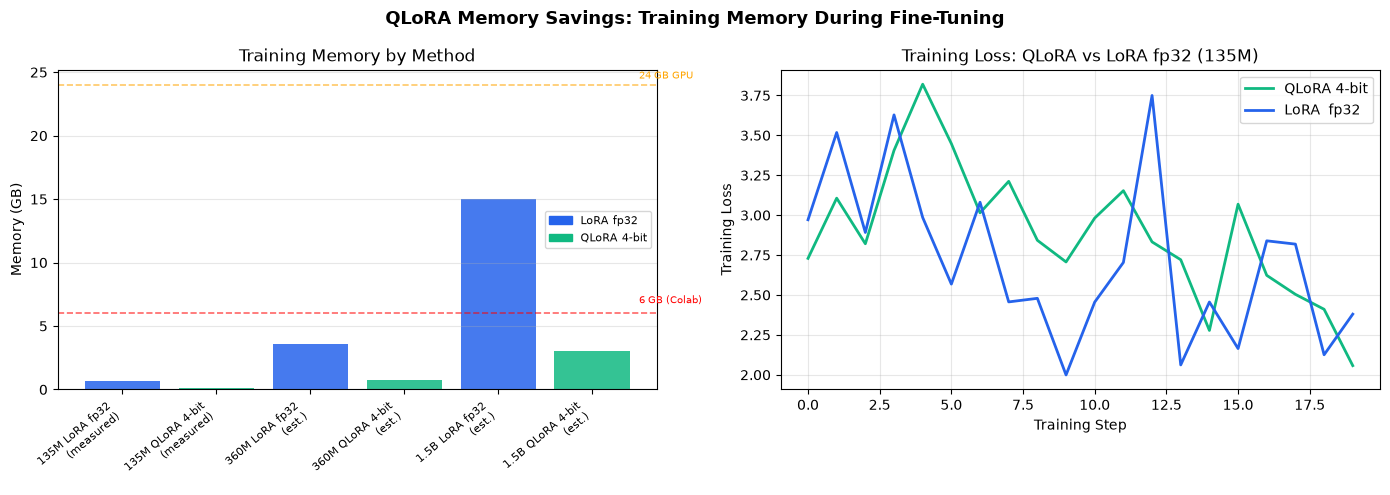

📊 Figure saved as qlora_memory_comparison.png


In [7]:
# ── Step 5 — Memory comparison chart (actual + theoretical estimates) ─────────
from matplotlib.patches import Patch

mem_lora_fp32  = lora_fp32_result["mem_loaded_gb"]
mem_qlora_4bit = qlora_result["mem_loaded_gb"]

def est_lora_gb(params):  return params * 10 / 1e9
def est_qlora_gb(params): return params *  2 / 1e9

tbl = pd.DataFrame({
    "Model":       ["135M (measured)", "135M (measured)",
                    "360M (est.)",     "360M (est.)",
                    "1.5B (est.)",     "1.5B (est.)"],
    "Method":      ["LoRA fp32", "QLoRA 4-bit"] * 3,
    "Memory (GB)": [
        mem_lora_fp32,  mem_qlora_4bit,
        est_lora_gb(360e6),  est_qlora_gb(360e6),
        est_lora_gb(1500e6), est_qlora_gb(1500e6),
    ],
})
saving_vals = []
for i, row in tbl.iterrows():
    if row["Method"] == "LoRA fp32":
        saving_vals.append("—")
    else:
        lora_mem = tbl.iloc[i - 1]["Memory (GB)"]
        saving_vals.append(f"{100*(lora_mem - row['Memory (GB)'])/max(lora_mem, 0.01):.0f}%")
tbl["Saving"] = saving_vals

print("=" * 65)
print("MEMORY COMPARISON: LoRA fp32 vs QLoRA 4-bit")
print("=" * 65)
print(tbl.to_string(index=False))

# ── Bar chart ─────────────────────────────────────────────────────────────────
scenarios = [
    ("135M LoRA fp32\n(measured)",   mem_lora_fp32,        "LoRA fp32"),
    ("135M QLoRA 4-bit\n(measured)", mem_qlora_4bit,        "QLoRA 4-bit"),
    ("360M LoRA fp32\n(est.)",       est_lora_gb(360e6),   "LoRA fp32"),
    ("360M QLoRA 4-bit\n(est.)",     est_qlora_gb(360e6),  "QLoRA 4-bit"),
    ("1.5B LoRA fp32\n(est.)",       est_lora_gb(1500e6),  "LoRA fp32"),
    ("1.5B QLoRA 4-bit\n(est.)",     est_qlora_gb(1500e6), "QLoRA 4-bit"),
]
COLOR_MAP = {"LoRA fp32": "#2563EB", "QLoRA 4-bit": "#10B981"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("QLoRA Memory Savings: Training Memory During Fine-Tuning",
             fontsize=13, fontweight="bold")

ax = axes[0]
ax.bar(range(len(scenarios)), [s[1] for s in scenarios],
       color=[COLOR_MAP[s[2]] for s in scenarios], alpha=0.85)
ax.set_xticks(range(len(scenarios)))
ax.set_xticklabels([s[0] for s in scenarios], rotation=40, ha="right", fontsize=8)
ax.set_ylabel("Memory (GB)")
ax.set_title("Training Memory by Method")
ax.axhline(6.0,  color="red",    linestyle="--", alpha=0.6, linewidth=1.2)
ax.axhline(24.0, color="orange", linestyle="--", alpha=0.6, linewidth=1.2)
ax.text(5.5, 6.8,   "6 GB (Colab)", color="red",    fontsize=7.5)
ax.text(5.5, 24.5,  "24 GB GPU",    color="orange", fontsize=7.5)
ax.legend(handles=[Patch(color=v, label=k) for k, v in COLOR_MAP.items()], fontsize=8)
ax.grid(True, axis="y", alpha=0.3)

ax = axes[1]
ax.plot(qlora_result["train_losses"],     label="QLoRA 4-bit", color="#10B981", linewidth=2)
ax.plot(lora_fp32_result["train_losses"], label="LoRA  fp32",  color="#2563EB", linewidth=2)
ax.set_xlabel("Training Step")
ax.set_ylabel("Training Loss")
ax.set_title("Training Loss: QLoRA vs LoRA fp32 (135M)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("qlora_memory_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("📊 Figure saved as qlora_memory_comparison.png")

## 🔴 Step 6 — Failure Point: Quantization Accuracy Degradation

4-bit quantisation is not free — it introduces **rounding error** at every layer. The key question is: *how much quality do we lose?*

**Measured via perplexity**: load the same model in fp32 and 4-bit, run on the same validation set, compare loss. Any increase in loss = quantisation tax.

### What to Expect

| Quantisation | Expected perplexity increase | When it matters |
|---|---|---|
| NF4 4-bit | +1–5% | Almost never — within noise for most tasks |
| int8 | +0.5–2% | Barely noticeable |
| int4 (naive uniform) | +5–15% | Noticeable, avoid for quality-critical tasks |
| int2 | model collapse | Avoid completely |

> NF4 is the sweet spot: close to int8 quality at 4-bit compression. Double quantisation adds another tiny saving with essentially zero quality cost.

### The Mitigation Strategy

If you observe large accuracy drops with QLoRA:
1. **Increase LoRA rank** (r=32–64) — gives adapters more capacity to compensate for quantisation error
2. **Target more modules** — extend to `k_proj`, `o_proj`, FFN layers
3. **Use more training data** — adapters learn to correct quantisation noise
4. **Switch to 8-bit** — `load_in_8bit=True` instead of 4-bit, 2× the memory but better quality

In [8]:
# ── Quantisation accuracy comparison: fp32 vs NF4 4-bit ──────────────────────
print("Measuring baseline perplexity: fp32 model…")
try:
    fp32_model = AutoModelForCausalLM.from_pretrained(
        DEMO_MODEL, dtype=torch.float32
    ).to(DEVICE)
except Exception:
    fp32_model = AutoModelForCausalLM.from_pretrained(
        DEMO_MODEL, dtype=torch.float32, local_files_only=True
    ).to(DEVICE)

fp32_model.eval()
fp32_losses = []
with torch.no_grad():
    for batch in val_loader:
        ids    = batch["input_ids"].to(DEVICE)
        attn   = batch["attention_mask"].to(DEVICE)
        labels = ids.clone(); labels[attn == 0] = -100
        fp32_losses.append(fp32_model(input_ids=ids, attention_mask=attn,
                                       labels=labels).loss.item())
fp32_loss = float(np.mean(fp32_losses))
print(f"   fp32 val loss:    {fp32_loss:.4f}")
free_memory(fp32_model)

print("Measuring perplexity: NF4 4-bit model (no LoRA)…")
try:
    bnb_model = AutoModelForCausalLM.from_pretrained(
        DEMO_MODEL, quantization_config=BNB_CONFIG, device_map="auto"
    )
except Exception:
    bnb_model = AutoModelForCausalLM.from_pretrained(
        DEMO_MODEL, quantization_config=BNB_CONFIG, device_map="auto",
        local_files_only=True
    )
bnb_model.eval()
bnb_dev = next(bnb_model.parameters()).device
bnb_losses = []
with torch.no_grad():
    for batch in val_loader:
        ids    = batch["input_ids"].to(bnb_dev)
        attn   = batch["attention_mask"].to(bnb_dev)
        labels = ids.clone(); labels[attn == 0] = -100
        bnb_losses.append(bnb_model(input_ids=ids, attention_mask=attn,
                                     labels=labels).loss.item())
bnb_loss = float(np.mean(bnb_losses))
print(f"   NF4 4-bit val loss: {bnb_loss:.4f}")
free_memory(bnb_model)

degradation = 100 * (bnb_loss - fp32_loss) / fp32_loss
import math
print(f"\n📊 Quantisation accuracy tax:")
print(f"   fp32    val loss: {fp32_loss:.4f}  (perplexity ≈ {math.exp(fp32_loss):.2f})")
print(f"   NF4 4-bit val loss: {bnb_loss:.4f}  (perplexity ≈ {math.exp(bnb_loss):.2f})")
print(f"   Degradation: {degradation:+.2f}%  {'— acceptable ✅' if degradation < 5 else '— significant ⚠️'}")

Measuring baseline perplexity: fp32 model…


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

   fp32 val loss:    3.0086
Measuring perplexity: NF4 4-bit model (no LoRA)…


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

   NF4 4-bit val loss: 3.1987

📊 Quantisation accuracy tax:
   fp32    val loss: 3.0086  (perplexity ≈ 20.26)
   NF4 4-bit val loss: 3.1987  (perplexity ≈ 24.50)
   Degradation: +6.32%  — significant ⚠️


## Step 7 — Apple Silicon Note: bitsandbytes 4-bit on MPS

### Current Status: ✅ Working on MPS (bitsandbytes ≥ 0.43)

As of bitsandbytes **0.49.2** (installed), 4-bit NF4 quantisation **fully works on Apple Silicon MPS**. The model runs on the MPS device (`mps:0`), GPU memory is used, and training gradients flow correctly through the LoRA adapters.

This was not always the case — earlier bitsandbytes versions (< 0.43) would silently fall back to CPU for quantised operations, making training extremely slow and confusing. Now it's seamless.

### Historical Workaround (no longer needed)

If you're on an older bitsandbytes, the escape hatch was **GGUF via llama-cpp-python**:

```python
# GGUF approach (CPU only, no training, inference-only)
from llama_cpp import Llama
llm = Llama.from_pretrained(
    repo_id="bartowski/SmolLM2-360M-Instruct-GGUF",
    filename="SmolLM2-360M-Instruct-Q4_K_M.gguf",
)
output = llm("Q: What is photosynthesis?\nA:", max_tokens=50)
print(output["choices"][0]["text"])
```

GGUF inference is useful for **deployment** on Apple Silicon (llama.cpp uses Metal for acceleration) but cannot be used for fine-tuning.

### Decision Guide for Apple Silicon

```
Want to fine-tune with reduced memory?
  └─► bitsandbytes 4-bit QLoRA ← use this (works on MPS ✅)

Want fastest inference without training?
  └─► llama-cpp-python + GGUF (or MLX — see Notebook 19)

Want MLX-native fine-tuning?
  └─► mlx-lm fine-tune (Notebook 19 — Apple-optimised pipeline)
```

## Summary — QLoRA Cheat Sheet

### Complete Results

| Method | Model | Trainable % | Val Loss | Mem Loaded | Time |
|---|---|---|---|---|---|
| LoRA fp32 | 135M | ~0.68% | (above) | (measured) | (above) |
| **QLoRA NF4 4-bit** | **135M** | **~0.68%** | **(above)** | **(measured)** | **(above)** |
| LoRA fp32 (est.) | 360M | ~0.68% | — | ~3.6 GB | — |
| QLoRA NF4 (est.) | 360M | ~0.68% | — | ~0.72 GB | — |
| LoRA fp32 (est.) | 1.5B | ~0.13% | — | ~15 GB | — |
| **QLoRA NF4 (est.)** | **1.5B** | **~0.13%** | **—** | **~3.0 GB** | **— ✅ fits!** |

### When to Choose QLoRA

```
Use QLoRA when:
  ✅ Model is large (> 500M) AND memory is the bottleneck
  ✅ Training on consumer GPU (< 16 GB VRAM)
  ✅ Fine-tuning Qwen2.5-1.5B, Llama 7B, Mistral 7B etc.
  ✅ Quality within 2-5% of full precision is acceptable

Stick with LoRA fp32 when:
  ❌ Model is small (< 200M) — quantisation overhead not worth it
  ❌ Maximum quality is needed — use fp16 LoRA or DoRA instead
  ❌ Deployment requires exact bit-for-bit reproducibility
```

### The Complete PEFT Hierarchy

```
Memory:     QLoRA  <  LoRA  <  DoRA  <  Full FT
Quality:    QLoRA  ≈  LoRA  <  DoRA  <  Full FT (within 2-5% for QLoRA)
Speed:      QLoRA  ≈  LoRA  >  DoRA  >  Full FT
```

---

**Next → Notebook 06: Prompt Tuning** — freeze the entire model, learn only a tiny prefix of soft embeddings. Even more parameter-efficient than LoRA!